In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")  # updated: local path instead of Colab /content path


In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
# TotalCharges is sometimes read as string (raw Kaggle CSV has blank " " entries),
# sometimes already numeric depending on the source file. Handle both cases:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank/invalid TotalCharges converted to NaN:", df["TotalCharges"].isnull().sum())


Blank/invalid TotalCharges converted to NaN: 11


In [10]:
print(df["TotalCharges"].isnull().sum())

11


In [11]:
df[df["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [12]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [13]:
print(df["TotalCharges"].isnull().sum())

0


In [14]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [15]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [16]:
print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [17]:
df["customerID"].nunique()

7043

In [18]:
df = df.drop(columns=["customerID"])

In [19]:
print(df.shape)
print(df.columns.tolist())

(7043, 20)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [21]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

In [22]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


In [23]:
print("Target distribution:")
print(y.value_counts(normalize=True))

Target distribution:
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [25]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

X_train: (5634, 19)
X_test : (1409, 19)

Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Test target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


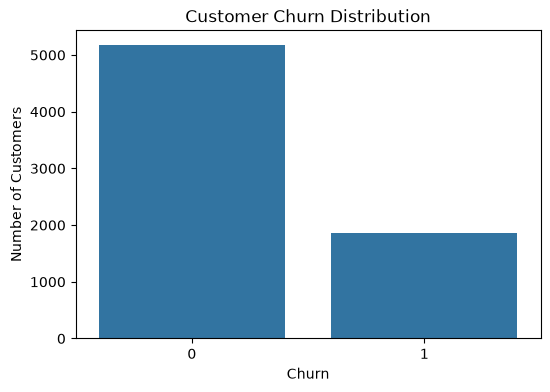

In [26]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [27]:
churn_rate = df["Churn"].value_counts(normalize=True) * 100

print(churn_rate)

Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


In [28]:
numeric_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

In [29]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00


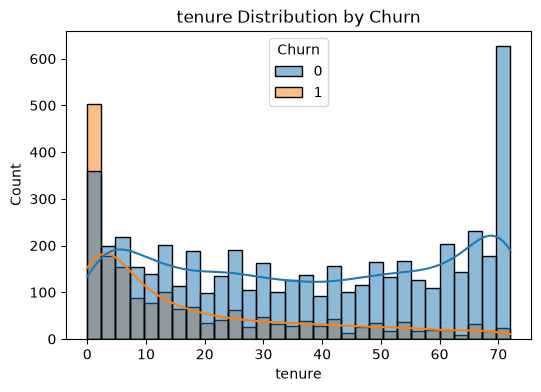

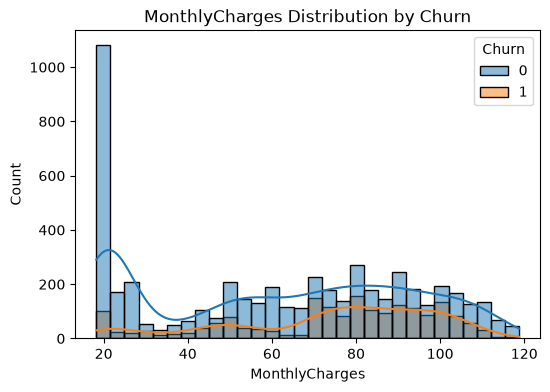

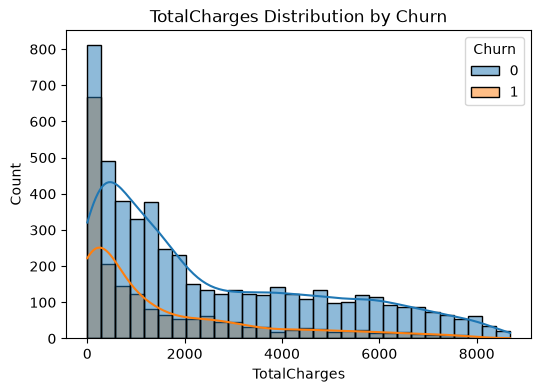

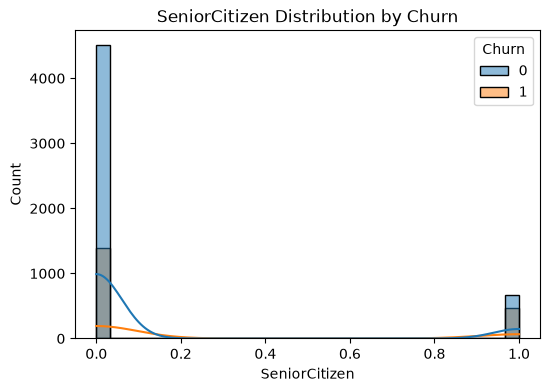

In [30]:
for col in numeric_cols:
    plt.figure(figsize=(6, 4))

    sns.histplot(
        data=df,
        x=col,
        hue="Churn",
        kde=True,
        bins=30
    )

    plt.title(f"{col} Distribution by Churn")
    plt.show()

In [31]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 60, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-60 months",
        "61-72 months"
    ]
)

In [32]:
tenure_churn = (
    df.groupby("tenure_group", observed=False)["Churn"]
      .mean()
      .mul(100)
)

print(tenure_churn)

tenure_group
0-12 months     47.678161
13-24 months    28.710938
25-48 months    20.388959
49-60 months    14.423077
61-72 months     6.609808
Name: Churn, dtype: float64


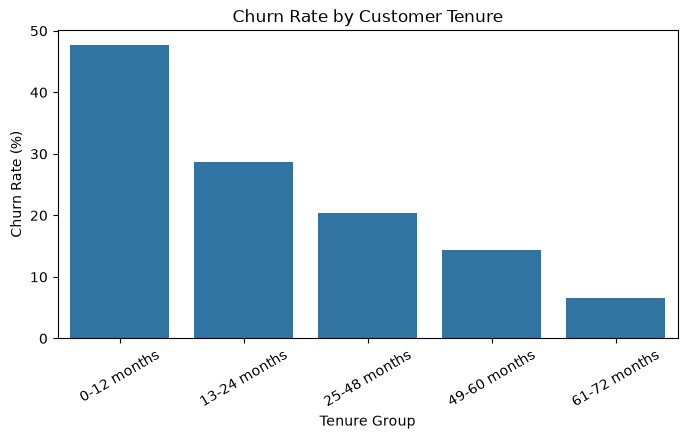

In [33]:
plt.figure(figsize=(8, 4))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values
)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)

plt.show()

In [34]:
df["monthly_charge_group"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 30, 60, 90, 120, np.inf],
    labels=[
        "0-30",
        "31-60",
        "61-90",
        "91-120",
        "120+"
    ]
)

In [35]:
charge_churn = (
    df.groupby("monthly_charge_group", observed=False)["Churn"]
      .mean()
      .mul(100)
)

print(charge_churn)

monthly_charge_group
0-30       9.800363
31-60     25.928854
61-90     33.906119
91-120    32.777458
120+            NaN
Name: Churn, dtype: float64


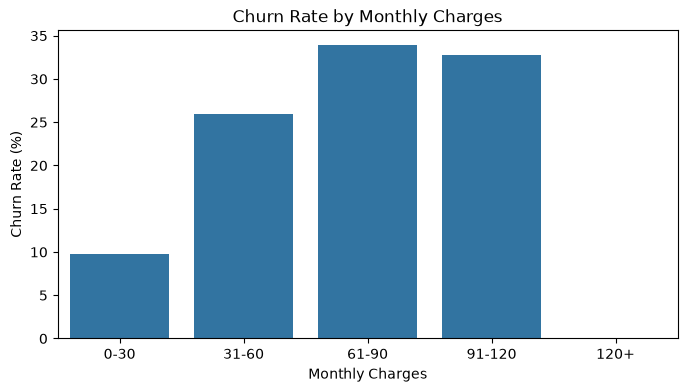

In [36]:
plt.figure(figsize=(8, 4))

sns.barplot(
    x=charge_churn.index,
    y=charge_churn.values
)

plt.title("Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Churn Rate (%)")

plt.show()

In [37]:
categorical_cols = X.select_dtypes(include="object").columns.tolist()

print(categorical_cols)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\infom\AppData\Local\Temp\ipykernel_18008\545684035.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns.tolist()


In [38]:
for col in categorical_cols:

    churn_rate = (
        df.groupby(col)["Churn"]
          .mean()
          .sort_values(ascending=False)
          .mul(100)
    )

    print(f"\n===== {col} =====")
    print(churn_rate)


===== gender =====
gender
Female    26.920872
Male      26.160338
Name: Churn, dtype: float64

===== Partner =====
Partner
No     32.957979
Yes    19.664903
Name: Churn, dtype: float64

===== Dependents =====
Dependents
No     31.279140
Yes    15.450237
Name: Churn, dtype: float64

===== PhoneService =====
PhoneService
Yes    26.709637
No     24.926686
Name: Churn, dtype: float64

===== MultipleLines =====
MultipleLines
Yes                 28.609896
No                  25.044248
No phone service    24.926686
Name: Churn, dtype: float64

===== InternetService =====
InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn, dtype: float64

===== OnlineSecurity =====
OnlineSecurity
No                     41.766724
Yes                    14.611194
No internet service     7.404980
Name: Churn, dtype: float64

===== OnlineBackup =====
OnlineBackup
No                     39.928756
Yes                    21.531494
No internet service     7.404980
N

In [39]:
important_cats = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling"
]

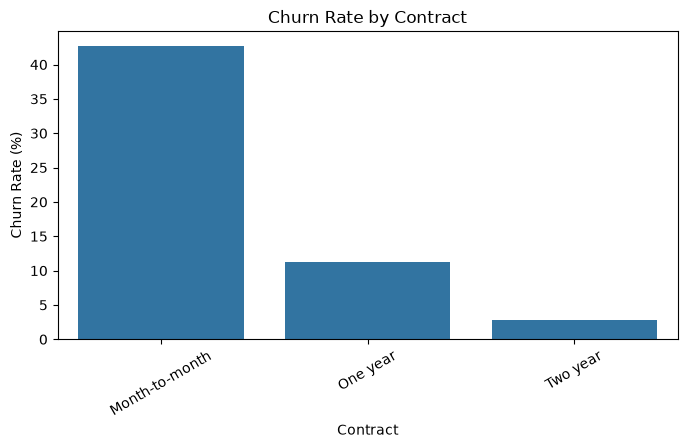

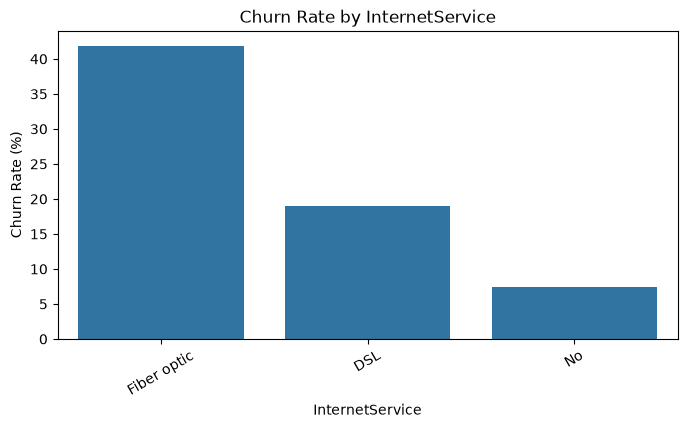

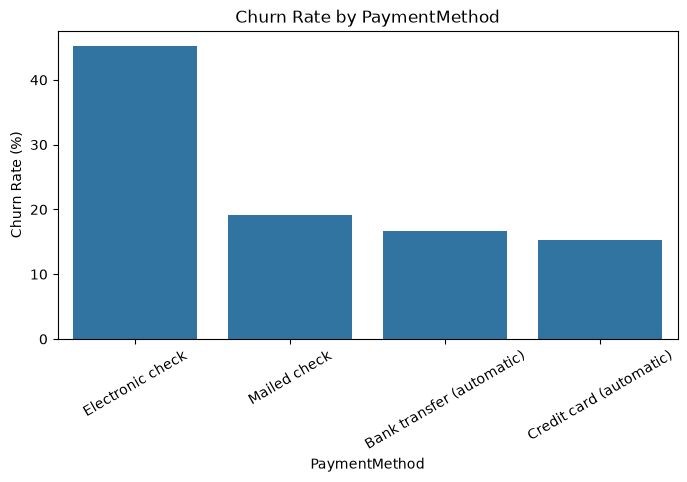

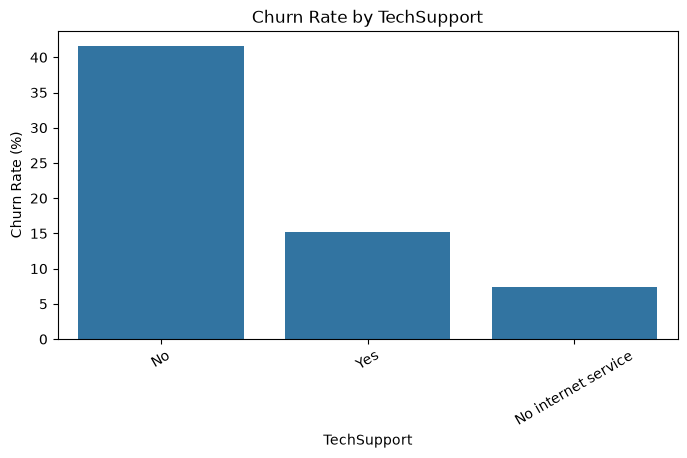

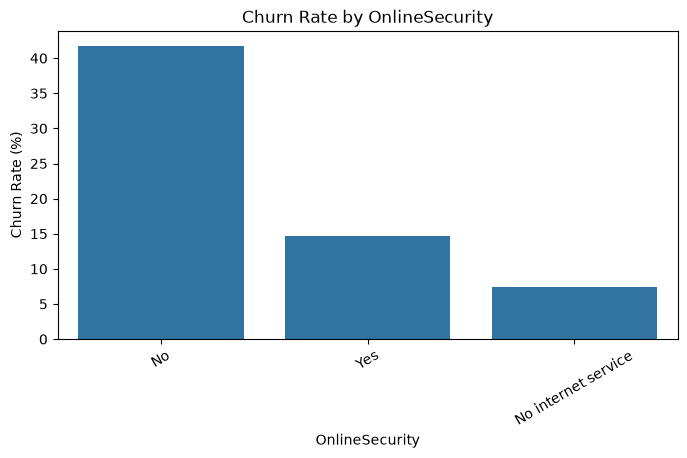

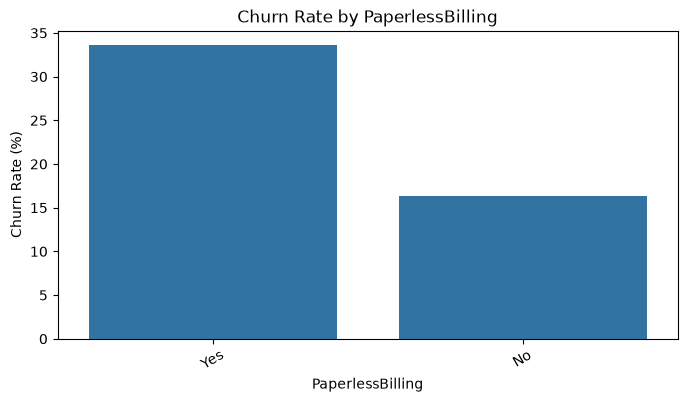

In [40]:
for col in important_cats:

    churn_rate = (
        df.groupby(col)["Churn"]
          .mean()
          .mul(100)
          .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 4))

    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values
    )

    plt.title(f"Churn Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=30)

    plt.show()

In [41]:
contract_churn = (
    df.groupby("Contract")["Churn"]
      .agg(["count", "mean"])
)

contract_churn["churn_rate"] = contract_churn["mean"] * 100

contract_churn = contract_churn.drop(columns="mean")

print(contract_churn)

                count  churn_rate
Contract                         
Month-to-month   3875   42.709677
One year         1473   11.269518
Two year         1695    2.831858


In [42]:
profile = df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean()

print(profile)

          tenure  MonthlyCharges  TotalCharges
Churn                                         
0      37.569965       61.265124   2549.911442
1      17.979133       74.441332   1531.796094


In [43]:
profile_median = df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].median()

print(profile_median)

       tenure  MonthlyCharges  TotalCharges
Churn                                      
0        38.0          64.425      1679.525
1        10.0          79.650       703.550


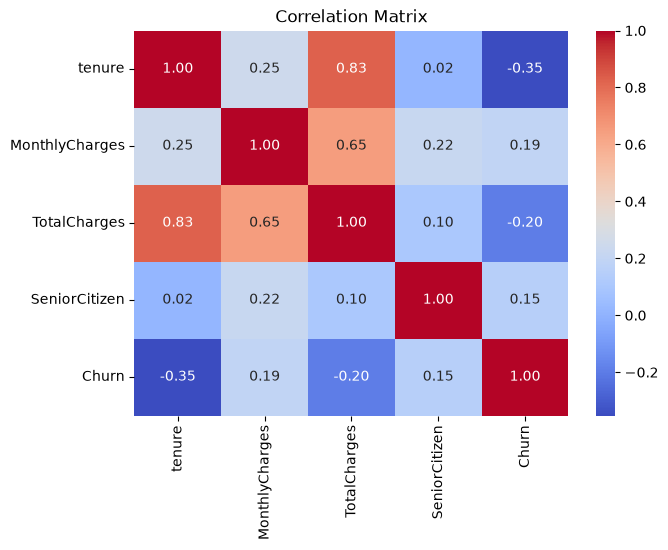

In [44]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]]
    .corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

Remove EDA-only columns

In [45]:
model_df = df.drop(
    columns=["tenure_group", "monthly_charge_group"]
)

In [46]:
print(model_df.shape)
print(model_df.columns.tolist())

(7043, 20)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [47]:
X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

In [48]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (7043, 19)
Target: (7043,)


In [49]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


C:\Users\infom\AppData\Local\Temp\ipykernel_18008\1838352015.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [50]:
# Train / Validation / Test split (60% / 20% / 20%)
# Validation set is used strictly for business-threshold selection.
# Test set remains untouched until final evaluation.

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTrain churn rate:", y_train.mean())
print("Validation churn rate:", y_val.mean())
print("Test churn rate:", y_test.mean())


Training set: (4225, 19)
Validation set: (1409, 19)
Test set: (1409, 19)

Train churn rate: 0.26532544378698225
Validation churn rate: 0.2654364797728886
Test churn rate: 0.2654364797728886


In [51]:
# Verify class distributions across splits
split_summary = pd.DataFrame({
    "Set": ["Train", "Validation", "Test"],
    "Samples": [len(y_train), len(y_val), len(y_test)],
    "Churn Count": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "Churn Rate (%)": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100]
})
print(split_summary.to_string(index=False))


       Set  Samples  Churn Count  Churn Rate (%)
     Train     4225         1121       26.532544
Validation     1409          374       26.543648
      Test     1409          374       26.543648


In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [53]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

In [54]:
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [55]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

In [56]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [57]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [58]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

In [59]:
cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [60]:
for metric in scoring.keys():
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

ACCURACY  : 0.7501 ± 0.0132
PRECISION : 0.5195 ± 0.0170
RECALL    : 0.7886 ± 0.0393
F1        : 0.6259 ± 0.0184
ROC_AUC   : 0.8436 ± 0.0185
PR_AUC    : 0.6578 ± 0.0455


In [61]:
logistic_pipeline.fit(X_train, y_train)

c:\Users\infom\OneDrive\Desktop\gouse\customer_churn_2\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [62]:
y_proba_logistic = logistic_pipeline.predict_proba(
    X_test
)[:, 1]

In [63]:
y_pred_logistic = (
    y_proba_logistic >= 0.5
).astype(int)

In [64]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

In [65]:
print("=== Logistic Regression Baseline ===")

print(
    classification_report(
        y_test,
        y_pred_logistic,
        digits=4
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba_logistic)
)

print(
    "PR-AUC:",
    average_precision_score(y_test, y_proba_logistic)
)

=== Logistic Regression Baseline ===
              precision    recall  f1-score   support

           0     0.9080    0.7246    0.8060      1035
           1     0.5111    0.7968    0.6228       374

    accuracy                         0.7438      1409
   macro avg     0.7096    0.7607    0.7144      1409
weighted avg     0.8027    0.7438    0.7574      1409

Confusion Matrix:
[[750 285]
 [ 76 298]]
ROC-AUC: 0.8306802035702292
PR-AUC: 0.6196212852451208


In [66]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    (
        "model",
        RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [67]:
rf_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [68]:
random_forest_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [69]:
y_proba_rf = random_forest_pipeline.predict_proba(
    X_test
)[:, 1]

In [70]:
y_pred_rf = (
    y_proba_rf >= 0.5
).astype(int)

In [71]:
print("=== Random Forest ===")

print(
    classification_report(
        y_test,
        y_pred_rf,
        digits=4
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba_rf)
)

print(
    "PR-AUC:",
    average_precision_score(y_test, y_proba_rf)
)

=== Random Forest ===
              precision    recall  f1-score   support

           0     0.8288    0.8792    0.8533      1035
           1     0.5981    0.4973    0.5431       374

    accuracy                         0.7779      1409
   macro avg     0.7134    0.6883    0.6982      1409
weighted avg     0.7675    0.7779    0.7709      1409

Confusion Matrix:
[[910 125]
 [188 186]]
ROC-AUC: 0.8036851894908161
PR-AUC: 0.5707470594562014


In [72]:
from xgboost import XGBClassifier

In [73]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    (
        "model",
        XGBClassifier(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )
    )
])

In [74]:
xgb_cv_results = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [75]:
for metric in scoring.keys():
    scores = xgb_cv_results[f"test_{metric}"]

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

ACCURACY  : 0.7979 ± 0.0117
PRECISION : 0.6409 ± 0.0322
RECALL    : 0.5460 ± 0.0229
F1        : 0.5891 ± 0.0198
ROC_AUC   : 0.8380 ± 0.0118
PR_AUC    : 0.6475 ± 0.0136


In [76]:
xgb_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [77]:
y_proba_xgb = xgb_pipeline.predict_proba(
    X_test
)[:, 1]

y_pred_xgb = (
    y_proba_xgb >= 0.5
).astype(int)

In [78]:
print("=== XGBoost ===")

print(
    classification_report(
        y_test,
        y_pred_xgb,
        digits=4
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba_xgb)
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        y_proba_xgb
    )
)

=== XGBoost ===
              precision    recall  f1-score   support

           0     0.8244    0.8754    0.8491      1035
           1     0.5839    0.4840    0.5292       374

    accuracy                         0.7715      1409
   macro avg     0.7041    0.6797    0.6892      1409
weighted avg     0.7605    0.7715    0.7642      1409

Confusion Matrix:
[[906 129]
 [193 181]]
ROC-AUC: 0.8156320235604122
PR-AUC: 0.6070674375839783


hyper paramete rtuning

In [79]:
from sklearn.model_selection import RandomizedSearchCV

In [80]:
xgb_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    (
        "model",
        XGBClassifier(
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )
    )
])

In [81]:
param_distributions = {
    "model__n_estimators": [100, 200, 300, 400, 500],

    "model__max_depth": [3, 4, 5, 6, 7],

    "model__learning_rate": [
        0.01,
        0.03,
        0.05,
        0.1,
        0.15
    ],

    "model__min_child_weight": [
        1,
        3,
        5,
        7
    ],

    "model__subsample": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__colsample_bytree": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__gamma": [
        0,
        0.1,
        0.3,
        0.5
    ],

    "model__reg_alpha": [
        0,
        0.01,
        0.1,
        1
    ],

    "model__reg_lambda": [
        1,
        1.5,
        2,
        5
    ]
}

In [82]:
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    return_train_score=False
)

In [83]:
xgb_random_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [0.6, 0.7, ...], 'model__gamma': [0, 0.1, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoo

In [84]:
print("Best PR-AUC:")
print(xgb_random_search.best_score_)

Best PR-AUC:
0.6663237029570845


In [85]:
print("\nBest Parameters:")
print(xgb_random_search.best_params_)


Best Parameters:
{'model__subsample': 0.6, 'model__reg_lambda': 1.5, 'model__reg_alpha': 0, 'model__n_estimators': 300, 'model__min_child_weight': 7, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__gamma': 0, 'model__colsample_bytree': 0.8}


In [86]:
best_xgb_model = xgb_random_search.best_estimator_

In [87]:
# Probabilities from the final tuned XGBoost pipeline
# Validation probabilities are used for threshold selection.
# Test probabilities are reserved for final evaluation.

y_proba_val = best_xgb_model.predict_proba(
    X_val
)[:, 1]

y_proba_tuned = best_xgb_model.predict_proba(
    X_test
)[:, 1]

# Standard 0.50 predictions on the untouched test set
y_pred_tuned = (
    y_proba_tuned >= 0.5
).astype(int)


In [88]:
print("=== Tuned XGBoost ===")

print(
    classification_report(
        y_test,
        y_pred_tuned,
        digits=4
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_tuned
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        y_proba_tuned
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        y_proba_tuned
    )
)

=== Tuned XGBoost ===
              precision    recall  f1-score   support

           0     0.8511    0.8560    0.8536      1035
           1     0.5951    0.5856    0.5903       374

    accuracy                         0.7842      1409
   macro avg     0.7231    0.7208    0.7219      1409
weighted avg     0.7832    0.7842    0.7837      1409

Confusion Matrix:
[[886 149]
 [155 219]]
ROC-AUC: 0.8327404479578394
PR-AUC: 0.6359953192284128


In [89]:
y_proba_tuned

array([0.0604002 , 0.2629235 , 0.21850017, ..., 0.33620095, 0.73547786,
       0.02381889], shape=(1409,), dtype=float32)

In [90]:
from sklearn.metrics import precision_score, recall_score, f1_score

# F1 threshold analysis is performed on the validation set,
# not the final test set.
thresholds = np.arange(0.05, 0.81, 0.01)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_proba_val >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)


    threshold  precision    recall        f1
0        0.05   0.350191  0.981283  0.516174
1        0.06   0.363366  0.981283  0.530347
2        0.07   0.371429  0.973262  0.537666
3        0.08   0.378519  0.970588  0.544636
4        0.09   0.386681  0.962567  0.551724
..        ...        ...       ...       ...
71       0.76   0.818182  0.240642  0.371901
72       0.77   0.813725  0.221925  0.348739
73       0.78   0.824742  0.213904  0.339703
74       0.79   0.813187  0.197861  0.318280
75       0.80   0.802326  0.184492  0.300000

[76 rows x 4 columns]


In [91]:
best_f1_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

print("Best F1 Threshold:")
print(best_f1_row)

Best F1 Threshold:
threshold    0.360000
precision    0.560694
recall       0.778075
f1           0.651736
Name: 31, dtype: float64


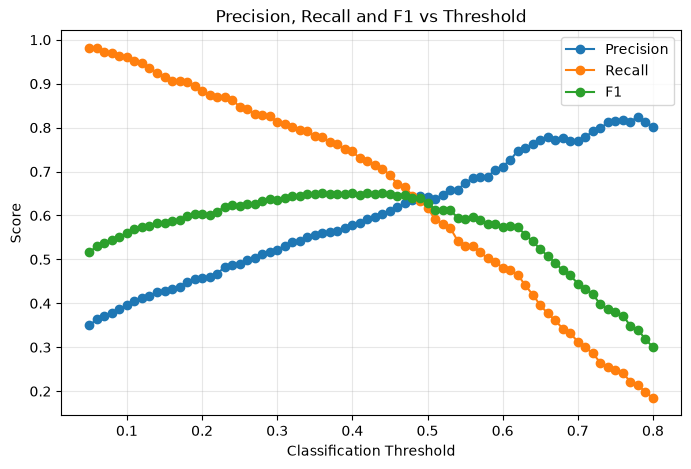

In [92]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Threshold")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [93]:
# ============================================================
# BUSINESS COST ASSUMPTIONS
# ============================================================

# Realistic retention business cost assumptions:
# - False Positive (FP): Offering retention incentive to a non-churner (~INR 500)
# - False Negative (FN): Losing customer lifetime/annual value (~INR 2,500)
# This 5:1 ratio prioritizes recall while protecting precision and preventing threshold collapse.

COST_FALSE_POSITIVE = 500
COST_FALSE_NEGATIVE = 2500


In [94]:
# ============================================================
# BUSINESS THRESHOLD SEARCH (ON VALIDATION SET)
# ============================================================

cost_results = []

for threshold in thresholds:

    # Threshold selection MUST use validation probabilities.
    y_pred_threshold = (
        y_proba_val >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred_threshold
    ).ravel()

    total_cost = (
        fp * COST_FALSE_POSITIVE
        + fn * COST_FALSE_NEGATIVE
    )

    cost_results.append({
        "threshold": round(threshold, 2),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "total_cost": total_cost
    })

cost_df = pd.DataFrame(cost_results)

print("Top 10 Thresholds by Minimum Validation Business Cost:")
print(cost_df.sort_values("total_cost").head(10).to_string(index=False))


Top 10 Thresholds by Minimum Validation Business Cost:
 threshold  TN  FP  FN  TP  total_cost
      0.23 686 349  49 325      297000
      0.24 696 339  51 323      297000
      0.18 620 415  36 338      297500
      0.19 633 402  39 335      298500
      0.12 530 505  20 354      302500
      0.14 567 468  28 346      304000
      0.13 545 490  24 350      305000
      0.17 600 435  35 339      305000
      0.20 644 391  44 330      305500
      0.26 718 317  59 315      306000


In [95]:
# Select the threshold with the minimum validation business cost.
best_cost_row = cost_df.loc[
    cost_df["total_cost"].idxmin()
]

best_business_threshold = float(
    best_cost_row["threshold"]
)

print("Best Business Threshold (Validation):")
print(best_cost_row)


Best Business Threshold (Validation):
threshold          0.23
TN               686.00
FP               349.00
FN                49.00
TP               325.00
total_cost    297000.00
Name: 18, dtype: float64


In [96]:
# ============================================================
# VALIDATION PERFORMANCE AT THE SELECTED BUSINESS THRESHOLD
# ============================================================

y_pred_val_business = (
    y_proba_val >= best_business_threshold
).astype(int)

print(
    f"\n===== Validation: Business Threshold "
    f"{best_business_threshold:.2f} ====="
)

print(
    classification_report(
        y_val,
        y_pred_val_business,
        digits=4,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_pred_val_business
    )
)

# Standard 0.50 validation comparison
y_pred_val_050 = (
    y_proba_val >= 0.50
).astype(int)

print("\n===== Validation: Standard Threshold 0.50 =====")

print(
    classification_report(
        y_val,
        y_pred_val_050,
        digits=4,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_val,
        y_pred_val_050
    )
)



===== Validation: Business Threshold 0.23 =====
              precision    recall  f1-score   support

           0     0.9333    0.6628    0.7751      1035
           1     0.4822    0.8690    0.6202       374

    accuracy                         0.7175      1409
   macro avg     0.7078    0.7659    0.6977      1409
weighted avg     0.8136    0.7175    0.7340      1409

Confusion Matrix:
[[686 349]
 [ 49 325]]

===== Validation: Standard Threshold 0.50 =====
              precision    recall  f1-score   support

           0     0.8637    0.8754    0.8695      1035
           1     0.6417    0.6176    0.6294       374

    accuracy                         0.8070      1409
   macro avg     0.7527    0.7465    0.7495      1409
weighted avg     0.8047    0.8070    0.8058      1409

Confusion Matrix:
[[906 129]
 [143 231]]


SHAP

In [97]:
!pip install shap


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [98]:
import shap
import matplotlib.pyplot as plt

c:\Users\infom\OneDrive\Desktop\gouse\customer_churn_2\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [99]:
# %whos removed — Jupyter-only magic, breaks when exported to a .py script


In [100]:
[x for x in dir() if "xgb" in x.lower() or "model" in x.lower()]

['XGBClassifier',
 'best_xgb_model',
 'model_df',
 'xgb_cv_results',
 'xgb_pipeline',
 'xgb_random_search',
 'xgb_tuning_pipeline',
 'y_pred_xgb',
 'y_proba_xgb']

In [101]:
# NOTE: this was exploratory — TreeExplainer needs the raw XGBoost model,
# not the whole imblearn Pipeline. Fixed properly a few cells below,
# after unwrapping best_xgb_model.named_steps['model'].


In [102]:
type(best_xgb_model)

imblearn.pipeline.Pipeline

In [103]:
type(xgb_pipeline)

imblearn.pipeline.Pipeline

In [104]:
print(type(xgb_pipeline))

<class 'imblearn.pipeline.Pipeline'>


In [105]:
print(type(best_xgb_model))

<class 'imblearn.pipeline.Pipeline'>


In [106]:
print(best_xgb_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
               

In [107]:
xgb_model = best_xgb_model.named_steps["model"]

In [108]:
print(type(xgb_model))

<class 'xgboost.sklearn.XGBClassifier'>


In [109]:
preprocessor = best_xgb_model.named_steps["preprocessor"]

In [110]:
print(type(preprocessor))

<class 'sklearn.compose._column_transformer.ColumnTransformer'>


In [111]:
X_test_transformed = preprocessor.transform(X_test)

In [112]:
X_test_transformed.shape

(1409, 45)

In [113]:
feature_names = preprocessor.get_feature_names_out()

print(len(feature_names))
print(feature_names)

45
['categorical__gender_Female' 'categorical__gender_Male'
 'categorical__Partner_No' 'categorical__Partner_Yes'
 'categorical__Dependents_No' 'categorical__Dependents_Yes'
 'categorical__PhoneService_No' 'categorical__PhoneService_Yes'
 'categorical__MultipleLines_No'
 'categorical__MultipleLines_No phone service'
 'categorical__MultipleLines_Yes' 'categorical__InternetService_DSL'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No' 'categorical__OnlineSecurity_No'
 'categorical__OnlineSecurity_No internet service'
 'categorical__OnlineSecurity_Yes' 'categorical__OnlineBackup_No'
 'categorical__OnlineBackup_No internet service'
 'categorical__OnlineBackup_Yes' 'categorical__DeviceProtection_No'
 'categorical__DeviceProtection_No internet service'
 'categorical__DeviceProtection_Yes' 'categorical__TechSupport_No'
 'categorical__TechSupport_No internet service'
 'categorical__TechSupport_Yes' 'categorical__StreamingTV_No'
 'categorical__StreamingTV_No interne

In [114]:
import shap

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test_transformed)

In [115]:
shap_values.shape

(1409, 45)

In [116]:
X_test_transformed.shape[1]

45

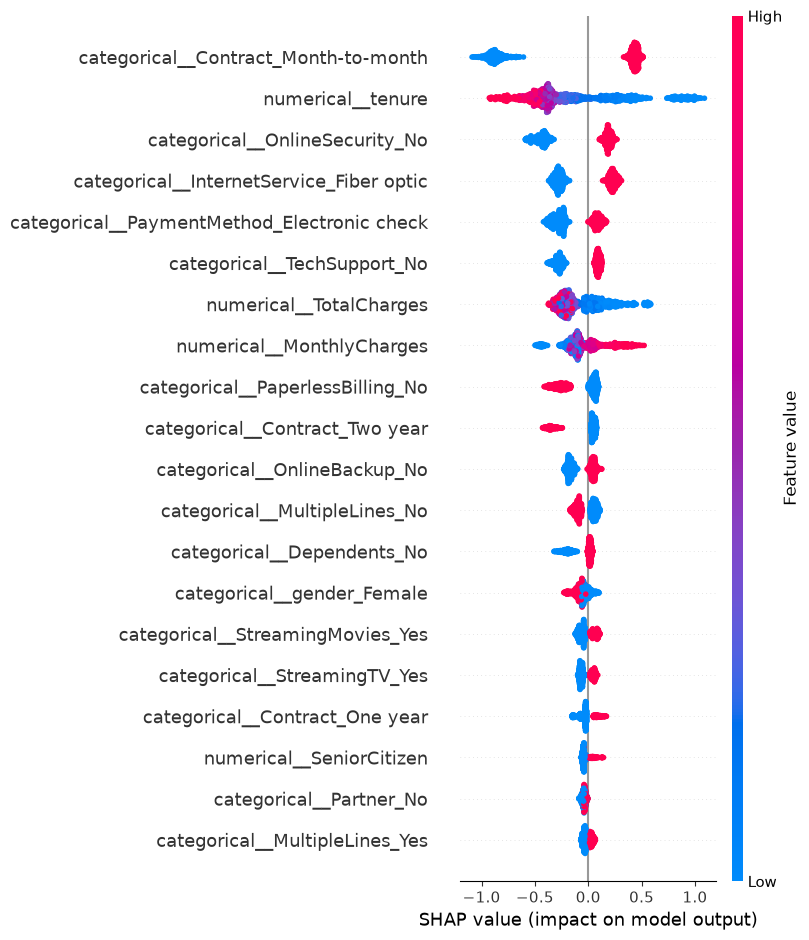

In [117]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names
)

In [118]:
import pandas as pd
import numpy as np

# Get original feature groups from the preprocessor
categorical_cols = preprocessor.transformers_[0][2]
numeric_cols = preprocessor.transformers_[1][2]

# Create mapping from transformed feature -> original feature
feature_mapping = {}

# Numerical features
for col in numeric_cols:
    feature_mapping[f"numerical__{col}"] = col

# Categorical features
for col in categorical_cols:
    prefix = f"categorical__{col}_"

    for feature_name in feature_names:
        if feature_name.startswith(prefix):
            feature_mapping[feature_name] = col

# Convert to DataFrame
shap_df = pd.DataFrame(
    shap_values,
    columns=feature_names
)

# Aggregate absolute SHAP values
aggregated_shap = pd.DataFrame(index=shap_df.index)

for original_feature in set(feature_mapping.values()):
    transformed_features = [
        feature for feature, original in feature_mapping.items()
        if original == original_feature
    ]

    aggregated_shap[original_feature] = (
        shap_df[transformed_features]
        .abs()
        .sum(axis=1)
    )

# Mean absolute SHAP importance
shap_importance = (
    aggregated_shap
    .mean()
    .sort_values(ascending=False)
)

print(shap_importance)

Contract            0.805721
tenure              0.422812
OnlineSecurity      0.327424
InternetService     0.280525
PaymentMethod       0.259478
TechSupport         0.207003
TotalCharges        0.182150
PaperlessBilling    0.168683
MonthlyCharges      0.154462
OnlineBackup        0.129507
MultipleLines       0.112824
Dependents          0.092873
StreamingMovies     0.089485
gender              0.080862
StreamingTV         0.073528
Partner             0.058494
SeniorCitizen       0.043225
DeviceProtection    0.032697
PhoneService        0.009884
dtype: float32


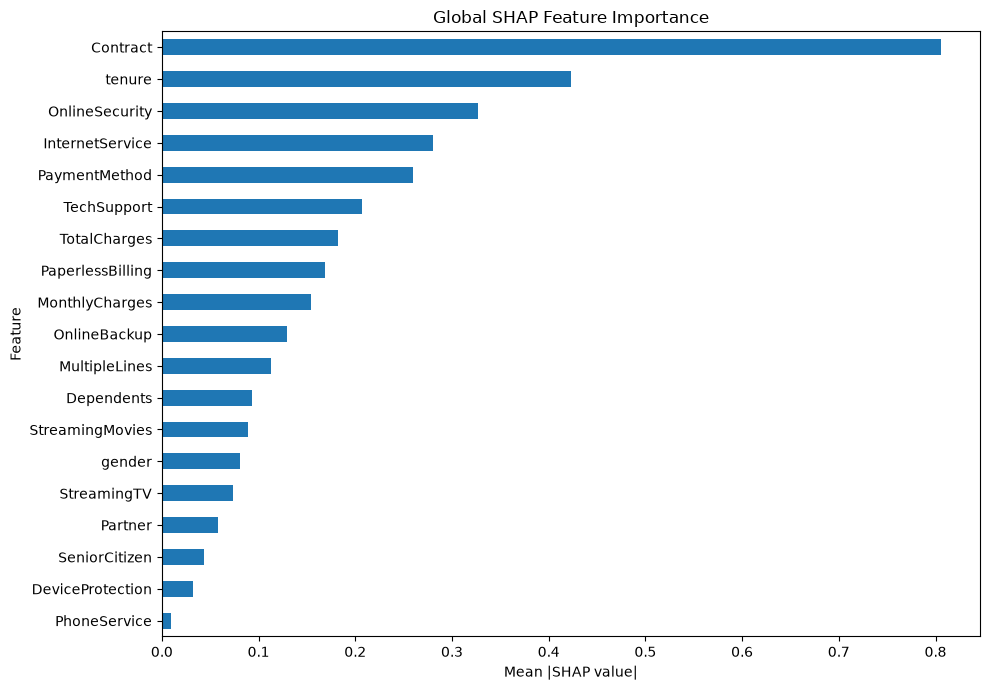

In [119]:
plt.figure(figsize=(10, 7))

shap_importance.sort_values().plot(
    kind="barh"
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance")
plt.tight_layout()

plt.show()

In [120]:
shap_importance_df = (
    shap_importance
    .reset_index()
)

shap_importance_df.columns = [
    "Feature",
    "Mean_Absolute_SHAP"
]

print(shap_importance_df)

             Feature  Mean_Absolute_SHAP
0           Contract            0.805721
1             tenure            0.422812
2     OnlineSecurity            0.327424
3    InternetService            0.280525
4      PaymentMethod            0.259478
5        TechSupport            0.207003
6       TotalCharges            0.182150
7   PaperlessBilling            0.168683
8     MonthlyCharges            0.154462
9       OnlineBackup            0.129507
10     MultipleLines            0.112824
11        Dependents            0.092873
12   StreamingMovies            0.089485
13            gender            0.080862
14       StreamingTV            0.073528
15           Partner            0.058494
16     SeniorCitizen            0.043225
17  DeviceProtection            0.032697
18      PhoneService            0.009884


In [121]:
print(shap_importance_df.to_string(index=False))

         Feature  Mean_Absolute_SHAP
        Contract            0.805721
          tenure            0.422812
  OnlineSecurity            0.327424
 InternetService            0.280525
   PaymentMethod            0.259478
     TechSupport            0.207003
    TotalCharges            0.182150
PaperlessBilling            0.168683
  MonthlyCharges            0.154462
    OnlineBackup            0.129507
   MultipleLines            0.112824
      Dependents            0.092873
 StreamingMovies            0.089485
          gender            0.080862
     StreamingTV            0.073528
         Partner            0.058494
   SeniorCitizen            0.043225
DeviceProtection            0.032697
    PhoneService            0.009884


In [122]:
# Select the highest-risk customer according to the FINAL tuned model.
high_risk_idx = np.argmax(y_proba_tuned)

print("Index:", high_risk_idx)
print("Churn probability:", y_proba_tuned[high_risk_idx])
print("Actual churn:", y_test.iloc[high_risk_idx])


Index: 391
Churn probability: 0.9248751
Actual churn: 1


In [123]:
X_test.iloc[high_risk_idx]

gender                          Male
SeniorCitizen                      1
Partner                           No
Dependents                        No
tenure                             1
PhoneService                     Yes
MultipleLines                    Yes
InternetService          Fiber optic
OnlineSecurity                    No
OnlineBackup                      No
DeviceProtection                  No
TechSupport                       No
StreamingTV                      Yes
StreamingMovies                  Yes
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
MonthlyCharges                  94.0
TotalCharges                    94.0
Name: 4800, dtype: object

In [124]:
print(
    "Churn probability:",
    y_proba_tuned[high_risk_idx]
)
print(X_test.iloc[high_risk_idx])


Churn probability: 0.9248751
gender                          Male
SeniorCitizen                      1
Partner                           No
Dependents                        No
tenure                             1
PhoneService                     Yes
MultipleLines                    Yes
InternetService          Fiber optic
OnlineSecurity                    No
OnlineBackup                      No
DeviceProtection                  No
TechSupport                       No
StreamingTV                      Yes
StreamingMovies                  Yes
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
MonthlyCharges                  94.0
TotalCharges                    94.0
Name: 4800, dtype: object


In [125]:
customer_idx = high_risk_idx

customer_shap = shap_values[customer_idx]
customer_data = X_test_transformed[customer_idx]

In [126]:
customer_explanation = shap.Explanation(
    values=customer_shap,
    base_values=explainer.expected_value,
    data=customer_data,
    feature_names=feature_names
)

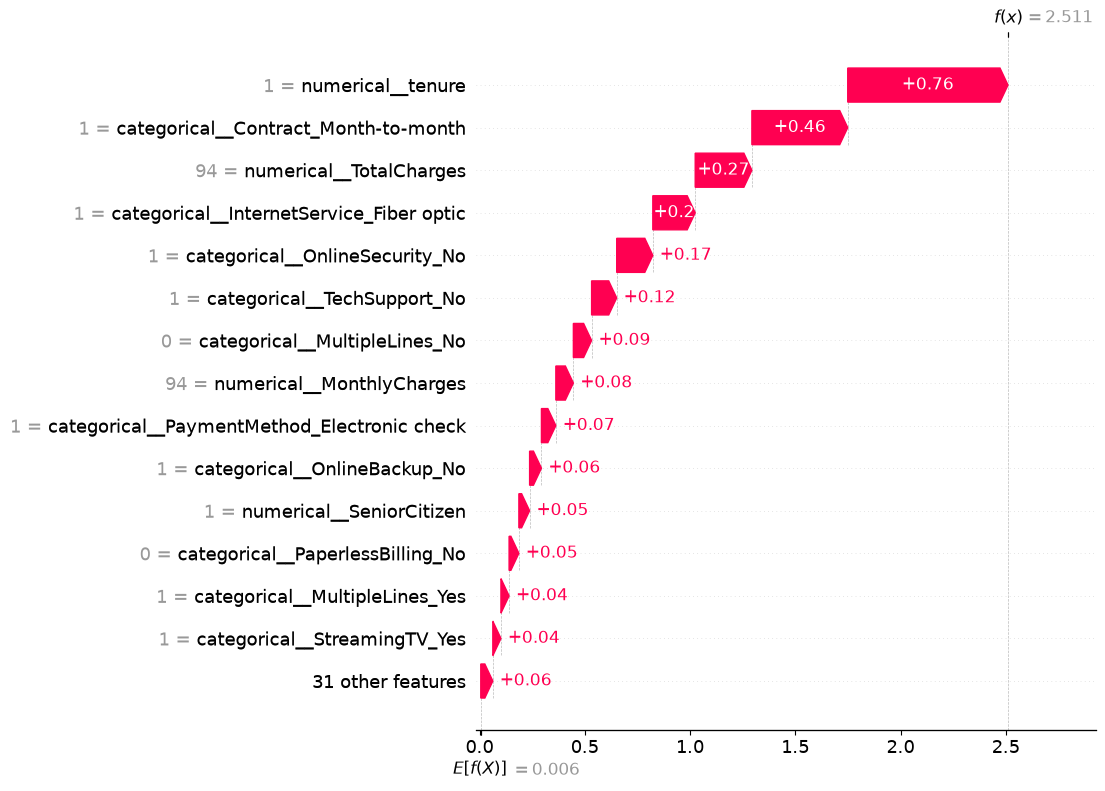

In [127]:
shap.plots.waterfall(customer_explanation, max_display=15)

In [128]:
customer_contributions = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": customer_shap
})

customer_contributions["Impact"] = np.where(
    customer_contributions["SHAP_Value"] > 0,
    "Increases Churn",
    "Decreases Churn"
)

customer_contributions["Abs_SHAP"] = (
    customer_contributions["SHAP_Value"].abs()
)

customer_contributions = (
    customer_contributions
    .sort_values("Abs_SHAP", ascending=False)
)

print(customer_contributions.head(15).to_string(index=False))

                                    Feature  SHAP_Value          Impact  Abs_SHAP
                          numerical__tenure    0.761379 Increases Churn  0.761379
       categorical__Contract_Month-to-month    0.455321 Increases Churn  0.455321
                    numerical__TotalCharges    0.269270 Increases Churn  0.269270
   categorical__InternetService_Fiber optic    0.201389 Increases Churn  0.201389
             categorical__OnlineSecurity_No    0.171559 Increases Churn  0.171559
                categorical__TechSupport_No    0.119222 Increases Churn  0.119222
              categorical__MultipleLines_No    0.086672 Increases Churn  0.086672
                  numerical__MonthlyCharges    0.083214 Increases Churn  0.083214
categorical__PaymentMethod_Electronic check    0.068474 Increases Churn  0.068474
               categorical__OnlineBackup_No    0.056183 Increases Churn  0.056183
                   numerical__SeniorCitizen    0.050950 Increases Churn  0.050950
           categ

In [129]:
# ============================================================
# FINAL TEST-SET EVALUATION
# ============================================================
# The business threshold was selected ONLY on the validation set.
# Now it is locked and evaluated once on the untouched test set.

y_pred_final = (
    y_proba_tuned >= best_business_threshold
).astype(int)


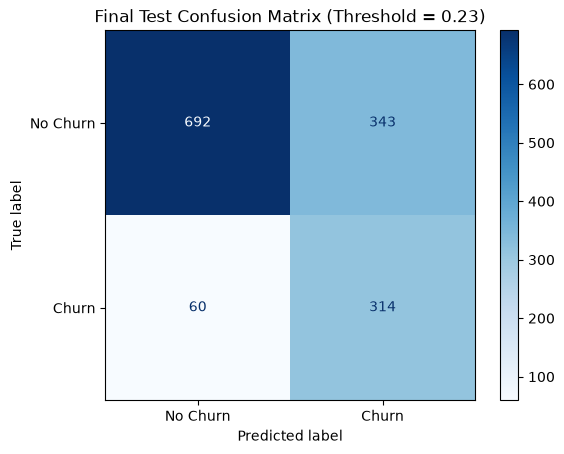

In [130]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_final
)

tn, fp, fn, tp = cm.ravel()

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")
plt.title(
    f"Final Test Confusion Matrix "
    f"(Threshold = {best_business_threshold:.2f})"
)
plt.show()


In [131]:
from sklearn.metrics import classification_report

print("=== FINAL TEST PERFORMANCE ===")

print(
    classification_report(
        y_test,
        y_pred_final,
        digits=4,
        zero_division=0
    )
)


=== FINAL TEST PERFORMANCE ===
              precision    recall  f1-score   support

           0     0.9202    0.6686    0.7745      1035
           1     0.4779    0.8396    0.6091       374

    accuracy                         0.7140      1409
   macro avg     0.6991    0.7541    0.6918      1409
weighted avg     0.8028    0.7140    0.7306      1409



In [132]:
# Final test-set business cost using the locked threshold
total_cost = (
    fp * COST_FALSE_POSITIVE
    + fn * COST_FALSE_NEGATIVE
)

print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print(
    f"Final Business Cost on Test Set: "
    f"INR {total_cost:,.0f}"
)


TN: 692
FP: 343
FN: 60
TP: 314
Final Business Cost on Test Set: INR 321,500


In [133]:
print(
    f"Locked Business Threshold: "
    f"{best_business_threshold:.2f}"
)

print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print(
    f"Final Test Business Cost: "
    f"INR {total_cost:,.0f}"
)

print(
    f"FP Cost Assumption: "
    f"INR {COST_FALSE_POSITIVE}"
)

print(
    f"FN Cost Assumption: "
    f"INR {COST_FALSE_NEGATIVE}"
)


Locked Business Threshold: 0.23
TN: 692
FP: 343
FN: 60
TP: 314
Final Test Business Cost: INR 321,500
FP Cost Assumption: INR 500
FN Cost Assumption: INR 2500


In [134]:
# ============================================================
# FINAL TEST COST COMPARISON: LOCKED THRESHOLD VS 0.50
# ============================================================

y_pred_test_050 = (
    y_proba_tuned >= 0.50
).astype(int)

tn_050, fp_050, fn_050, tp_050 = confusion_matrix(
    y_test,
    y_pred_test_050
).ravel()

cost_050 = (
    fp_050 * COST_FALSE_POSITIVE
    + fn_050 * COST_FALSE_NEGATIVE
)

print(f"Locked business threshold: {best_business_threshold:.2f}")
print(f"Business cost at locked threshold: INR {total_cost:,.0f}")

print("\nStandard threshold: 0.50")
print(f"Business cost at 0.50: INR {cost_050:,.0f}")
print(f"Business cost saved by tuning threshold: INR {cost_050 - total_cost:,.0f}")


Locked business threshold: 0.23
Business cost at locked threshold: INR 321,500

Standard threshold: 0.50
Business cost at 0.50: INR 462,000
Business cost saved by tuning threshold: INR 140,500


In [135]:
print(
    "\nThreshold was selected strictly on validation data and "
    "evaluated on the untouched test data."
)

print(
    f"Locked threshold: {best_business_threshold:.2f}"
)



Threshold was selected strictly on validation data and evaluated on the untouched test data.
Locked threshold: 0.23


In [136]:
# The threshold is NOT hardcoded.
# It is automatically calculated from the validation-set
# business-cost search above.
business_threshold = best_business_threshold

print(
    f"Business threshold to deploy: "
    f"{business_threshold:.2f}"
)


Business threshold to deploy: 0.23


In [137]:
# Confirm the final test confusion matrix and cost
cm = confusion_matrix(
    y_test,
    y_pred_final
)

tn, fp, fn, tp = cm.ravel()

print("Final Threshold:", business_threshold)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

print(
    "Final Test Business Cost:",
    f"INR {fp * COST_FALSE_POSITIVE + fn * COST_FALSE_NEGATIVE:,.0f}"
)


Final Threshold: 0.23
TN: 692
FP: 343
FN: 60
TP: 314
Final Test Business Cost: INR 321,500


In [138]:
print(best_xgb_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
               

In [139]:
print(best_xgb_model.named_steps)

{'preprocessor': ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod']),
                                ('numerical', 'passthrough',
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges'])]), 'smote': SMOTE(random_state=42), 'model': XGBClassifier(base_score=None, booster=None, callbacks=None,
              cols

In [140]:
print(best_xgb_model.named_steps["model"])

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=7, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)


In [141]:
print(best_xgb_model.named_steps.keys())

dict_keys(['preprocessor', 'smote', 'model'])


In [142]:
print(best_xgb_model.named_steps["model"])

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=7, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)


In [143]:
import joblib

joblib.dump(
    best_xgb_model,
    "customer_churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [144]:
loaded_model = joblib.load("customer_churn_model.pkl")

print(type(loaded_model))

<class 'imblearn.pipeline.Pipeline'>


In [145]:
sample_customer = X_test.iloc[[0]]

probability = loaded_model.predict_proba(
    sample_customer
)[0, 1]

prediction = int(
    probability >= business_threshold
)

print("Churn probability:", probability)
print("Prediction:", prediction)
print("Business threshold:", business_threshold)


Churn probability: 0.060400203
Prediction: 0
Business threshold: 0.23


In [146]:
# FIX: best_xgb_model is already a full Pipeline (preprocessor + SMOTE + model)
# from RandomizedSearchCV.best_estimator_. Wrapping it in another preprocessor
# double-transforms the data. best_xgb_model IS the final pipeline.
final_pipeline = best_xgb_model


In [147]:
joblib.dump(final_pipeline, "customer_churn_pipeline.pkl")

['customer_churn_pipeline.pkl']

## Save final artifacts for the Streamlit app

The final deployed decision threshold is the threshold automatically selected
on the validation set using the documented business costs.

The untouched test set is used only for final evaluation.

The Streamlit app can load:
- the fitted preprocessor
- the raw XGBoost model
- SHAP feature names
- the automatically selected business threshold
- categorical and numerical feature lists

The SHAP explainer is rebuilt at app load time to avoid serialization/version issues.


In [148]:
import joblib

# best_xgb_model is the final fitted Pipeline:
# preprocessor -> SMOTE -> tuned XGBoost

fitted_preprocessor = best_xgb_model.named_steps["preprocessor"]
fitted_xgb_model = best_xgb_model.named_steps["model"]

shap_feature_names = list(
    fitted_preprocessor.get_feature_names_out()
)

# Save preprocessing pipeline
joblib.dump(
    fitted_preprocessor,
    "preprocessor.pkl"
)

# Save raw XGBoost model in XGBoost's native JSON format
fitted_xgb_model.save_model(
    "xgb_model.json"
)

# Save SHAP feature names
joblib.dump(
    shap_feature_names,
    "shap_feature_names.pkl"
)

# Save the AUTOMATICALLY SELECTED business threshold
joblib.dump(
    business_threshold,
    "business_threshold.pkl"
)

# Save feature lists
joblib.dump(
    list(categorical_features),
    "categorical_features.pkl"
)

joblib.dump(
    list(numerical_features),
    "numerical_features.pkl"
)

# Save business-cost assumptions for reproducibility
business_costs = {
    "false_positive_cost": COST_FALSE_POSITIVE,
    "false_negative_cost": COST_FALSE_NEGATIVE,
    "threshold_selection_dataset": "validation",
    "selected_threshold": business_threshold
}

joblib.dump(
    business_costs,
    "business_costs.pkl"
)

print(
    "Saved: preprocessor.pkl, xgb_model.json, "
    "shap_feature_names.pkl, business_threshold.pkl, "
    "categorical_features.pkl, numerical_features.pkl, "
    "business_costs.pkl"
)

print(
    f"Saved business threshold: {business_threshold:.2f}"
)

print("SHAP explainer will be rebuilt at app load time.")


Saved: preprocessor.pkl, xgb_model.json, shap_feature_names.pkl, business_threshold.pkl, categorical_features.pkl, numerical_features.pkl, business_costs.pkl
Saved business threshold: 0.23
SHAP explainer will be rebuilt at app load time.
